# Baseline — No Augmentation

**Project:** Arabic Text Augmentation for Low-Resource Classification  
**Dataset:** Arabic Sentiment Tweets Dataset (ASTD)  
**Classifier:** MARBERT (`UBC-NLP/MARBERT`)  
**Task:** Four-class Arabic tweet classification (`OBJ`, `NEG`, `NEUTRAL`, `POS`)

## Notebook purpose

This is the cleaned, final **baseline reporting notebook**. It verifies the prepared ASTD splits, loads the six completed baseline experiment results, reports the selected model's independent test evaluation, and regenerates the figures used in the research report.

**Important:** The six baseline training runs and the selected model's final test evaluation were completed previously. This notebook reads their saved result files; it does not silently retrain models or repeat test evaluation when `Run All` is selected. The training configuration is documented below for reproducibility.


## 1. Experimental protocol

The baseline uses the original training examples without text augmentation. Three low-resource training fractions were evaluated:

- 10% of the approved training split
- 25% of the approved training split
- 50% of the approved training split

Two baseline configurations were compared at each fraction: **Unweighted** and **Weighted V2**. This produces six validation experiments.

The best configuration was selected using **Validation Macro-F1**. Only the selected configuration, Weighted V2 at 25%, has a final independent test result in this notebook.

### Data leakage safeguards

- The official validation and test splits are kept separate from training.
- Low-resource subsets are loaded from the prepared `low_resource_splits_v2` files.
- Validation results are used for model selection.
- Test results are reported only for the selected model.
- No test examples are used for training or augmentation.

### Label interpretation

The dataset code `NEUTRAL` is retained as supplied by ASTD. In the original ASTD description, this code refers to **subjective mixed** sentiment; it should not be silently reinterpreted as ordinary neutral sentiment.


## 2. Imports and display settings

Load only the libraries needed for dataset checks, result tables, and figures. Model training is not started by this reporting notebook.

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

print("Imports completed successfully.")


Imports completed successfully.


## 3. Project configuration

Define the ASTD label mapping, the pretrained classifier used in the completed experiments, the random seed, and the expected project folders.

In [2]:
PROJECT_NAME = "Arabic Text Augmentation for Low-Resource Classification"

MODEL_NAME = "UBC-NLP/MARBERT"
SEED = 42
MAX_LENGTH = 128

LABEL2ID = {
    "OBJ": 0,
    "NEG": 1,
    "NEUTRAL": 2,
    "POS": 3,
}
ID2LABEL = {value: key for key, value in LABEL2ID.items()}
CLASS_NAMES = list(LABEL2ID.keys())

TRAINING_FRACTIONS = [10, 25, 50]

print("Project:", PROJECT_NAME)
print("Classifier:", MODEL_NAME)
print("Seed:", SEED)
print("Maximum sequence length:", MAX_LENGTH)
print("Label mapping:", LABEL2ID)


Project: Arabic Text Augmentation for Low-Resource Classification
Classifier: UBC-NLP/MARBERT
Seed: 42
Maximum sequence length: 128
Label mapping: {'OBJ': 0, 'NEG': 1, 'NEUTRAL': 2, 'POS': 3}


## 4. Locate the project directory

This cell searches the current folder and its parent folders. It supports running the notebook either from the project root or from the `notebooks` folder. It also accepts an explicit `ASTD_PROJECT_ROOT` environment variable.

In [3]:
def locate_project_root():
    configured_root = os.environ.get("ASTD_PROJECT_ROOT")

    candidates = []
    if configured_root:
        candidates.append(Path(configured_root).expanduser().resolve())

    current = Path.cwd().resolve()
    candidates.extend([current, *current.parents])

    required_files = [
        Path("data/processed/astd_train.csv"),
        Path("data/processed/astd_validation.csv"),
        Path("data/processed/astd_test.csv"),
        Path("reports/final_baseline/final_baseline_results_table.csv"),
    ]

    for candidate in candidates:
        if all((candidate / relative_path).is_file()
               for relative_path in required_files):
            return candidate

    checked = "\\n".join(str(path) for path in candidates)
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook from the "
        "arabic-text-augmentation-low-resource project, or set "
        "ASTD_PROJECT_ROOT to the project folder. Checked:\\n" + checked
    )


PROJECT_ROOT = locate_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FINAL_BASELINE_DIR = REPORTS_DIR / "final_baseline"
FINAL_TEST_DIR = REPORTS_DIR / "final_test"
FIGURES_DIR = FINAL_BASELINE_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_DIR)
print("Baseline reports:", FINAL_BASELINE_DIR)


Project root: C:\Users\tami8\Videos\arabic-text-augmentation-low-resource
Processed data: C:\Users\tami8\Videos\arabic-text-augmentation-low-resource\data\processed
Baseline reports: C:\Users\tami8\Videos\arabic-text-augmentation-low-resource\reports\final_baseline


## 5. Load the prepared ASTD datasets

Load the cleaned training, validation, and test CSV files. This cell checks required columns and missing values without displaying individual tweet text.

In [4]:
DATA_FILES = {
    "train": DATA_DIR / "astd_train.csv",
    "validation": DATA_DIR / "astd_validation.csv",
    "test": DATA_DIR / "astd_test.csv",
}

for split_name, file_path in DATA_FILES.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing {split_name} dataset: {file_path}")

train_df = pd.read_csv(DATA_FILES["train"], encoding="utf-8-sig")
val_df = pd.read_csv(DATA_FILES["validation"], encoding="utf-8-sig")
test_df = pd.read_csv(DATA_FILES["test"], encoding="utf-8-sig")

required_columns = {"text", "label"}
for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(
            f"{split_name} data is missing required columns: {sorted(missing_columns)}"
        )

    missing_values = frame[["text", "label"]].isna().sum()
    if missing_values.any():
        raise ValueError(
            f"Missing text/label values in {split_name}: {missing_values.to_dict()}"
        )

    unknown_labels = set(frame["label"].astype(str).unique()) - set(LABEL2ID)
    if unknown_labels:
        raise ValueError(
            f"Unexpected labels in {split_name}: {sorted(unknown_labels)}"
        )

print(f"Training rows:   {len(train_df):,}")
print(f"Validation rows: {len(val_df):,}")
print(f"Test rows:       {len(test_df):,}")
print("Required columns, labels, and missing-value checks passed.")


Training rows:   6,005
Validation rows: 1,997
Test rows:       1,999
Required columns, labels, and missing-value checks passed.


## 6. Verify the low-resource training subsets

Load the already prepared nested training subsets. These files are the inputs used by the baseline comparison. The cell checks file existence, label validity, and unique row identifiers when available.

In [5]:
SPLIT_DIR = DATA_DIR / "low_resource_splits_v2"
low_resource_splits = {}

for percentage in TRAINING_FRACTIONS:
    split_path = SPLIT_DIR / f"train_{percentage}pct.csv"

    if not split_path.is_file():
        raise FileNotFoundError(f"Missing low-resource split: {split_path}")

    subset = pd.read_csv(split_path, encoding="utf-8-sig")

    missing_columns = required_columns - set(subset.columns)
    if missing_columns:
        raise ValueError(
            f"{split_path.name} is missing columns: {sorted(missing_columns)}"
        )

    unknown_labels = set(subset["label"].astype(str).unique()) - set(LABEL2ID)
    if unknown_labels:
        raise ValueError(
            f"Unexpected labels in {split_path.name}: {sorted(unknown_labels)}"
        )

    if subset[["text", "label"]].isna().any().any():
        raise ValueError(f"Missing text/label values in {split_path.name}")

    if "row_id" in subset.columns and subset["row_id"].duplicated().any():
        raise ValueError(f"Duplicate row_id values in {split_path.name}")

    low_resource_splits[percentage] = subset

split_summary = pd.DataFrame([
    {
        "Training fraction": f"{percentage}%",
        "Number of rows": len(frame),
        "Number of classes": frame["label"].nunique(),
    }
    for percentage, frame in low_resource_splits.items()
])

display(split_summary)
print("All three low-resource subsets loaded and validated.")


,Training fraction,Number of rows,Number of classes
0,10%,600,4
1,25%,1501,4
2,50%,3002,4


All three low-resource subsets loaded and validated.


## 7. Dataset class distribution

Summarize the class distribution without printing or exposing individual tweet records. The class distribution is important when interpreting Accuracy and Macro-F1.

In [6]:
def class_distribution(frame, split_name):
    counts = (
        frame["label"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )

    return pd.DataFrame({
        "Split": split_name,
        "Class": counts.index,
        "Count": counts.values,
        "Percentage": counts.values / len(frame) * 100,
    })


distribution_table = pd.concat(
    [
        class_distribution(train_df, "Training"),
        class_distribution(val_df, "Validation"),
        class_distribution(test_df, "Test"),
    ],
    ignore_index=True,
)

display(
    distribution_table.pivot(
        index="Class",
        columns="Split",
        values="Count"
    ).reindex(CLASS_NAMES)
)

print("Dataset distribution summary:")
display(distribution_table.round(2))


Split,Test,Training,Validation
Class,,,
OBJ,1338,4012,1336
NEG,336,1012,336
NEUTRAL,166,500,166
POS,159,481,159


Dataset distribution summary:


,Split,Class,Count,Percentage
0,Training,OBJ,4012,66.8100
1,Training,NEG,1012,16.8500
2,Training,NEUTRAL,500,8.3300
3,Training,POS,481,8.0100
4,Validation,OBJ,1336,66.9000
5,Validation,NEG,336,16.8300
6,Validation,NEUTRAL,166,8.3100
7,Validation,POS,159,7.9600
8,Test,OBJ,1338,66.9300
9,Test,NEG,336,16.8100


## 8. Baseline model and recorded training configuration

The completed experiments used the pretrained **MARBERT** sequence classifier (`UBC-NLP/MARBERT`) with four output labels.

The baseline notebook recorded the following common settings:

| Setting | Value |
|---|---:|
| Maximum token length | 128 |
| Random seed | 42 |
| Training batch size | 1 |
| Gradient accumulation steps | 2 |
| Learning rate | 2e-5 |
| Maximum epochs | 3 |
| Model selection metric | Validation Macro-F1 |

The six validation runs compare Unweighted and Weighted V2 configurations at 10%, 25%, and 50%. The final reporting cells below load the saved experiment outputs instead of re-running the training process.

**Why training is not repeated by `Run All`:** the training runs have already been completed and their result files are stored in `reports/`. Re-running them would be computationally expensive, could overwrite checkpoints, and is not necessary to reproduce the tables and figures in this report notebook.


## 9. Load and validate the six baseline experiments

Load the saved six-experiment result table. The expected table contains validation metrics for all six runs, while final test metrics are populated only for the model selected using Validation Macro-F1.

In [7]:
RESULTS_PATH = FINAL_BASELINE_DIR / "final_baseline_results_table.csv"

if not RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Baseline results file not found: {RESULTS_PATH}")

baseline_results = pd.read_csv(RESULTS_PATH, encoding="utf-8-sig")

required_result_columns = [
    "Method",
    "Training Fraction",
    "Best Epoch",
    "Validation Accuracy",
    "Validation Macro-F1",
    "Validation Weighted-F1",
    "Selected for Final Test",
    "Test Accuracy",
    "Test Macro-F1",
    "Test Weighted-F1",
    "Test Samples",
]

missing_columns = set(required_result_columns) - set(baseline_results.columns)
if missing_columns:
    raise ValueError(
        f"Baseline results file is missing columns: {sorted(missing_columns)}"
    )

if len(baseline_results) != 6:
    raise ValueError(
        f"Expected six baseline experiments, found {len(baseline_results)}"
    )

for metric_column in [
    "Validation Accuracy",
    "Validation Macro-F1",
    "Validation Weighted-F1",
]:
    baseline_results[metric_column] = pd.to_numeric(
        baseline_results[metric_column], errors="raise"
    )

selected_mask = (
    baseline_results["Selected for Final Test"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes"])
)

if selected_mask.sum() != 1:
    raise ValueError(
        "Exactly one baseline experiment must be marked as selected for final test."
    )

selected_result = baseline_results.loc[selected_mask].iloc[0]

if (
    selected_result["Method"] != "Weighted V2"
    or selected_result["Training Fraction"] != "25%"
):
    raise ValueError(
        "The saved selected configuration differs from the documented "
        "Weighted V2 25% final-test evaluation. Review the source results."
    )

print("Six baseline experiments verified.")
print(
    "Selected configuration:",
    selected_result["Method"],
    selected_result["Training Fraction"]
)


Six baseline experiments verified.
Selected configuration: Weighted V2 25%


## 10. Validation results: comparison of all six experiments

The main comparison is based on validation results. Macro-F1 is the primary selection metric because the ASTD classes are imbalanced.

In [8]:
validation_columns = [
    "Method",
    "Training Fraction",
    "Best Epoch",
    "Validation Accuracy",
    "Validation Macro-F1",
    "Validation Weighted-F1",
]

validation_results = baseline_results[validation_columns].copy()

fraction_order = {"10%": 10, "25%": 25, "50%": 50}
validation_results["_fraction_order"] = (
    validation_results["Training Fraction"].map(fraction_order)
)

validation_results = (
    validation_results
    .sort_values(["_fraction_order", "Method"])
    .drop(columns="_fraction_order")
    .reset_index(drop=True)
)

display(validation_results.round(4))

best_validation_row = baseline_results.loc[
    baseline_results["Validation Macro-F1"].idxmax()
]

print(
    "Highest validation Macro-F1:",
    f"{best_validation_row['Validation Macro-F1']:.2%}",
    "—",
    best_validation_row["Method"],
    best_validation_row["Training Fraction"],
)


,Method,Training Fraction,Best Epoch,Validation Accuracy,Validation Macro-F1,Validation Weighted-F1
0,Unweighted,10%,3,0.5834,0.3915,0.5912
1,Weighted V2,10%,2,0.6865,0.4053,0.6605
2,Unweighted,25%,3,0.6845,0.3383,0.6346
3,Weighted V2,25%,3,0.7141,0.4963,0.6983
4,Unweighted,50%,3,0.7011,0.3812,0.6346
5,Weighted V2,50%,2,0.7151,0.4489,0.6806


Highest validation Macro-F1: 49.63% — Weighted V2 25%


## 11. Load the selected model's final test summary

The saved test summary should contain one row: the selected Weighted V2 model trained with 25% of the approved training data. Test results are reported here for final evaluation only.

In [9]:
TEST_SUMMARY_PATH = FINAL_TEST_DIR / "final_test_summary.csv"

if not TEST_SUMMARY_PATH.is_file():
    raise FileNotFoundError(
        f"Final test summary not found: {TEST_SUMMARY_PATH}"
    )

test_summary = pd.read_csv(TEST_SUMMARY_PATH, encoding="utf-8-sig")

if len(test_summary) != 1:
    raise ValueError(
        f"Expected one selected-model test summary row, found {len(test_summary)}"
    )

test_row = test_summary.iloc[0]

if test_row["Model"] != "Original Weighted V2 - 25%":
    raise ValueError("Unexpected model in final test summary.")

if int(test_row["Test Samples"]) != len(test_df):
    raise ValueError(
        "The saved test sample count does not match the loaded ASTD test split."
    )

print("Selected model:", test_row["Model"])
print("Training fraction:", test_row["Training Fraction"])
print("Test examples:", int(test_row["Test Samples"]))

display(test_summary.round(4))


Selected model: Original Weighted V2 - 25%
Training fraction: 25%
Test examples: 1999


,Model,Training Fraction,Best Validation Macro-F1,Test Samples,Test Accuracy,Test Macro-F1,Test Weighted-F1
0,Original Weighted V2 - 25%,25%,0.4963,1999,0.6843,0.4575,0.6718


## 12. Per-class test performance and confusion matrix

Load the saved per-class classification report and multiclass confusion matrix. These files provide the detailed evaluation of the selected model.

In [10]:
CLASS_REPORT_PATH = FINAL_TEST_DIR / "final_test_classification_report.csv"
CONFUSION_PATH = FINAL_TEST_DIR / "final_test_confusion_matrix.csv"

for file_path in [CLASS_REPORT_PATH, CONFUSION_PATH]:
    if not file_path.is_file():
        raise FileNotFoundError(f"Required final-test report not found: {file_path}")

class_report = pd.read_csv(CLASS_REPORT_PATH, index_col=0, encoding="utf-8-sig")
confusion_matrix_df = pd.read_csv(CONFUSION_PATH, index_col=0, encoding="utf-8-sig")

if not set(CLASS_NAMES).issubset(class_report.index):
    raise ValueError("One or more ASTD classes are missing from the classification report.")

expected_rows = [f"Actual {name}" for name in CLASS_NAMES]
expected_columns = [f"Predicted {name}" for name in CLASS_NAMES]

if (
    confusion_matrix_df.shape != (4, 4)
    or not set(expected_rows).issubset(confusion_matrix_df.index)
    or not set(expected_columns).issubset(confusion_matrix_df.columns)
):
    raise ValueError("The saved confusion matrix does not have the expected 4 × 4 layout.")

confusion_matrix_df = confusion_matrix_df.loc[expected_rows, expected_columns]
confusion_matrix_values = confusion_matrix_df.to_numpy(dtype=int)

if confusion_matrix_values.sum() != len(test_df):
    raise ValueError(
        "Confusion matrix total does not equal the number of test examples."
    )

print("Per-class test metrics:")
display(class_report.loc[CLASS_NAMES].round(4))

print("Confusion matrix:")
display(confusion_matrix_df)


Per-class test metrics:


,precision,recall,f1-score,support
OBJ,0.8053,0.8221,0.8136,1338.0000
NEG,0.4486,0.6101,0.5170,336.0000
NEUTRAL,0.2658,0.1265,0.1714,166.0000
POS,0.4330,0.2642,0.3281,159.0000


Confusion matrix:


,Predicted OBJ,Predicted NEG,Predicted NEUTRAL,Predicted POS
Actual OBJ,1100,160,32,46
Actual NEG,113,205,14,4
Actual NEUTRAL,59,81,21,5
Actual POS,94,11,12,42


## 13. Figure export helper

Use one helper to save each chart in both PNG (300 dpi) and PDF formats. The charts are saved as they are created, so the notebook does not regenerate them in a separate pass.


In [11]:
def save_report_figure(fig, filename):
    fig.tight_layout()

    png_path = FIGURES_DIR / f"{filename}.png"
    pdf_path = FIGURES_DIR / f"{filename}.pdf"

    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"Saved {png_path.name} and {pdf_path.name}")


## 14. Validation Macro-F1 comparison

This figure compares the primary selection metric across the Unweighted and Weighted V2 baselines at each training fraction.

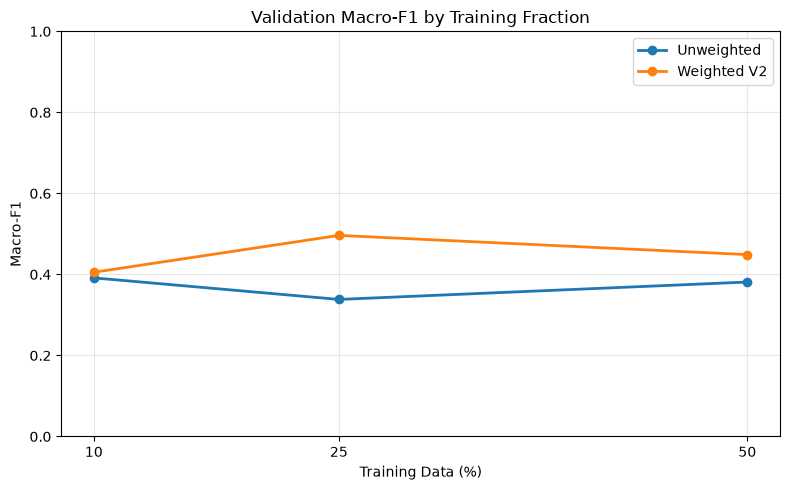

Saved fig1_validation_macro_f1.png and fig1_validation_macro_f1.pdf


In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

for method in ["Unweighted", "Weighted V2"]:
    subset = validation_results[
        validation_results["Method"] == method
    ].copy()

    subset["_fraction"] = (
        subset["Training Fraction"]
        .map(fraction_order)
    )
    subset = subset.sort_values("_fraction")

    ax.plot(
        subset["_fraction"],
        subset["Validation Macro-F1"],
        marker="o",
        linewidth=2,
        label=method,
    )

ax.set_title("Validation Macro-F1 by Training Fraction")
ax.set_xlabel("Training Data (%)")
ax.set_ylabel("Macro-F1")
ax.set_xticks([10, 25, 50])
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
save_report_figure(fig, "fig1_validation_macro_f1")


## 15. Validation Accuracy and Weighted-F1

These additional figures provide context for the Macro-F1 comparison. Accuracy and Weighted-F1 are reported alongside Macro-F1, not as replacements for it.

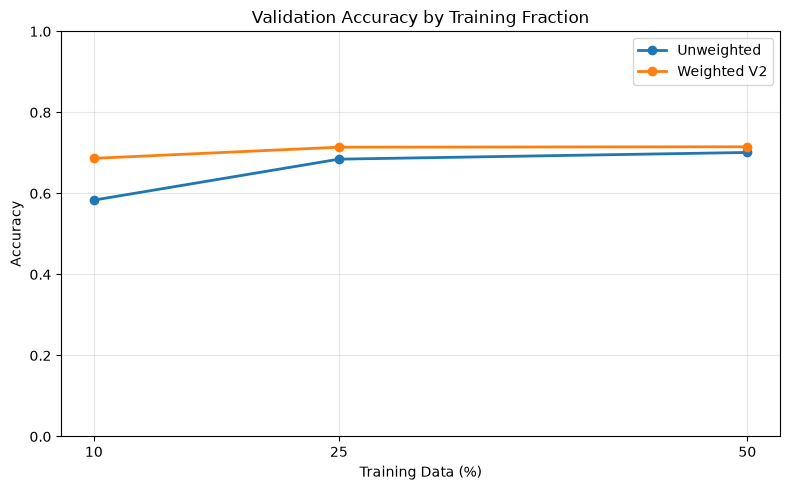

Saved fig2_validation_accuracy.png and fig2_validation_accuracy.pdf


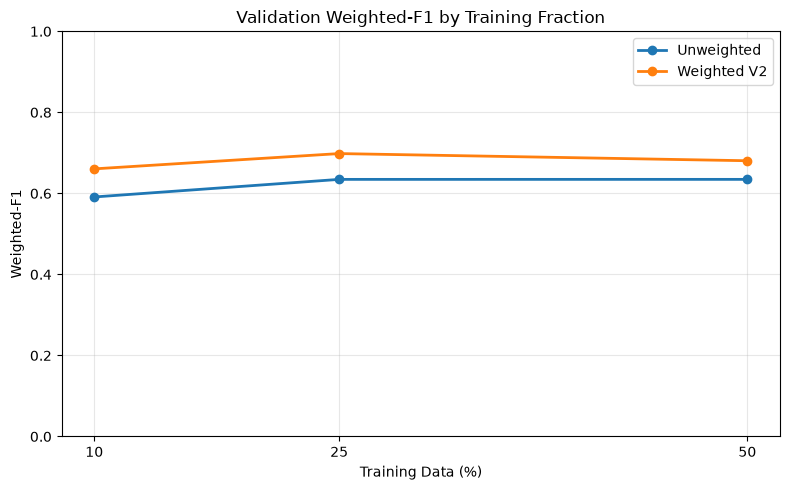

Saved fig3_validation_weighted_f1.png and fig3_validation_weighted_f1.pdf


In [13]:
# Figure 2: Validation Accuracy
fig, ax = plt.subplots(figsize=(8, 5))
for method in ["Unweighted", "Weighted V2"]:
    subset = validation_results[validation_results["Method"] == method].copy()
    subset["_fraction"] = subset["Training Fraction"].map(fraction_order)
    subset = subset.sort_values("_fraction")
    ax.plot(subset["_fraction"], subset["Validation Accuracy"], marker="o", linewidth=2, label=method)
ax.set_title("Validation Accuracy by Training Fraction")
ax.set_xlabel("Training Data (%)")
ax.set_ylabel("Accuracy")
ax.set_xticks([10, 25, 50])
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
save_report_figure(fig, "fig2_validation_accuracy")

# Figure 3: Validation Weighted-F1
fig, ax = plt.subplots(figsize=(8, 5))
for method in ["Unweighted", "Weighted V2"]:
    subset = validation_results[validation_results["Method"] == method].copy()
    subset["_fraction"] = subset["Training Fraction"].map(fraction_order)
    subset = subset.sort_values("_fraction")
    ax.plot(subset["_fraction"], subset["Validation Weighted-F1"], marker="o", linewidth=2, label=method)
ax.set_title("Validation Weighted-F1 by Training Fraction")
ax.set_xlabel("Training Data (%)")
ax.set_ylabel("Weighted-F1")
ax.set_xticks([10, 25, 50])
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
save_report_figure(fig, "fig3_validation_weighted_f1")


## 16. Final test metrics for the selected model

Only the selected Weighted V2 25% model is shown here because the test set was reserved for final independent evaluation.

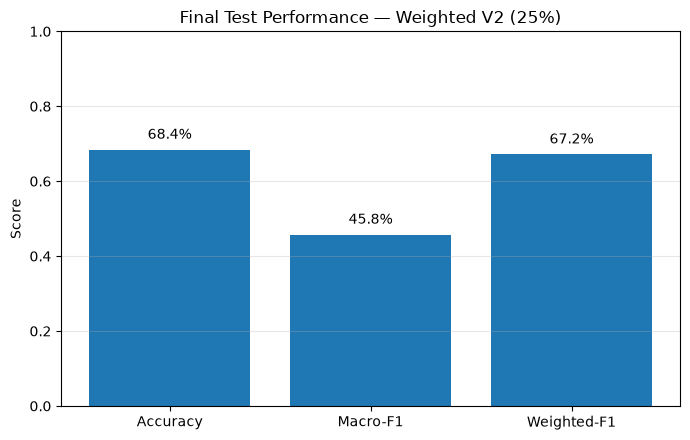

Saved fig4_final_test_metrics.png and fig4_final_test_metrics.pdf


In [14]:
test_metric_names = ["Accuracy", "Macro-F1", "Weighted-F1"]
test_metric_values = [
    float(test_row["Test Accuracy"]),
    float(test_row["Test Macro-F1"]),
    float(test_row["Test Weighted-F1"]),
]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(test_metric_names, test_metric_values)

ax.set_title("Final Test Performance — Weighted V2 (25%)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, test_metric_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.1%}",
        ha="center",
        va="bottom",
    )

save_report_figure(fig, "fig4_final_test_metrics")


## 17. Per-class F1-score

The per-class results show whether the selected model performs consistently across all four ASTD labels.

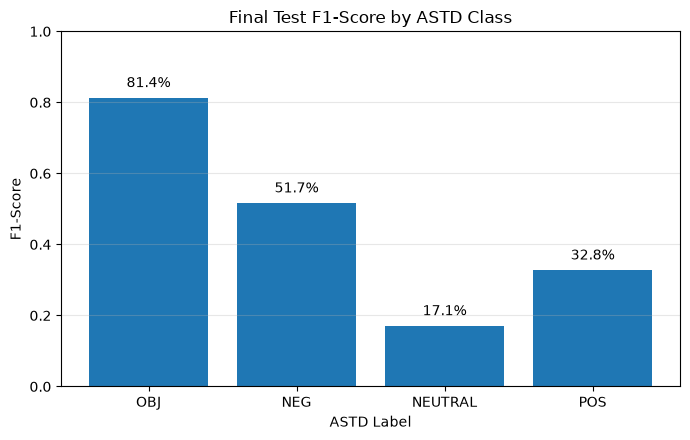

Saved fig5_test_per_class_f1.png and fig5_test_per_class_f1.pdf


In [15]:
class_f1 = class_report.loc[CLASS_NAMES, "f1-score"].astype(float)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(CLASS_NAMES, class_f1.values)

ax.set_title("Final Test F1-Score by ASTD Class")
ax.set_xlabel("ASTD Label")
ax.set_ylabel("F1-Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, class_f1.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.1%}",
        ha="center",
        va="bottom",
    )

save_report_figure(fig, "fig5_test_per_class_f1")


## 18. Final test confusion matrix

Rows represent actual labels and columns represent predicted labels. The values are counts of test examples.

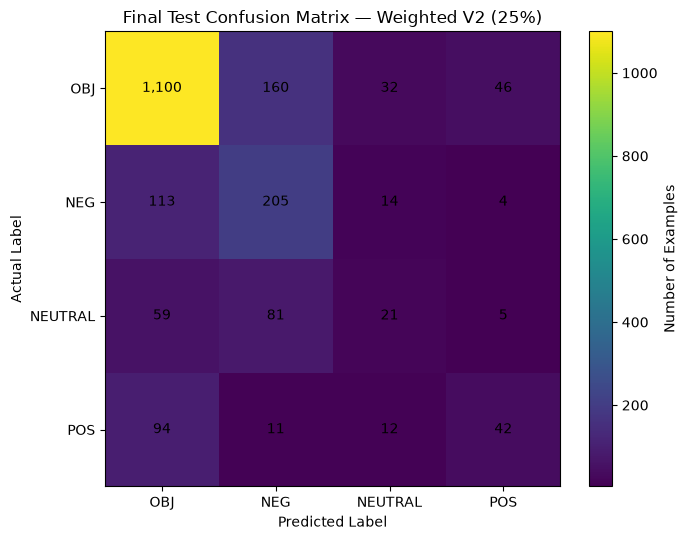

Saved fig6_test_confusion_matrix.png and fig6_test_confusion_matrix.pdf


In [16]:
fig, ax = plt.subplots(figsize=(7, 5.5))

image = ax.imshow(confusion_matrix_values, interpolation="nearest")
ax.set_title("Final Test Confusion Matrix — Weighted V2 (25%)")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_xticks(range(4), CLASS_NAMES)
ax.set_yticks(range(4), CLASS_NAMES)

for row in range(4):
    for column in range(4):
        ax.text(
            column,
            row,
            f"{confusion_matrix_values[row, column]:,}",
            ha="center",
            va="center",
        )

fig.colorbar(image, ax=ax, label="Number of Examples")
save_report_figure(fig, "fig6_test_confusion_matrix")


## 19. Verify exported figures

Save the figures in both PNG and PDF formats under `reports/final_baseline/figures/`. These can be inserted into the IEEE report.

In [17]:
saved_png = sorted(FIGURES_DIR.glob("*.png"))
saved_pdf = sorted(FIGURES_DIR.glob("*.pdf"))

print("Figure directory:", FIGURES_DIR)
print("PNG files:", len(saved_png))
print("PDF files:", len(saved_pdf))

for path in saved_png + saved_pdf:
    print(path.name)

if len(saved_png) != 6 or len(saved_pdf) != 6:
    raise RuntimeError(
        "Some report figures were not exported. Review the plotting cells above."
    )

print("\nFigure export check passed.")


Figure directory: C:\Users\tami8\Videos\arabic-text-augmentation-low-resource\reports\final_baseline\figures
PNG files: 6
PDF files: 6
fig1_validation_macro_f1.png
fig2_validation_accuracy.png
fig3_validation_weighted_f1.png
fig4_final_test_metrics.png
fig5_test_per_class_f1.png
fig6_test_confusion_matrix.png
fig1_validation_macro_f1.pdf
fig2_validation_accuracy.pdf
fig3_validation_weighted_f1.pdf
fig4_final_test_metrics.pdf
fig5_test_per_class_f1.pdf
fig6_test_confusion_matrix.pdf

Figure export check passed.


## 20. Baseline findings

The highest validation Macro-F1 among the six baseline experiments was achieved by **Weighted V2 using 25% of the training data**.

The selected configuration achieved:

- **Validation Macro-F1:** 49.63%
- **Test Accuracy:** 68.43%
- **Test Macro-F1:** 45.75%
- **Test Weighted-F1:** 67.18%

The per-class test results show stronger performance on `OBJ` and `NEG` than on `NEUTRAL` and `POS`. This is important because the ASTD dataset is imbalanced. The relatively low `NEUTRAL` F1-score indicates that the baseline still has difficulty with the subjective-mixed category.

These results are the **no-augmentation baseline**. They should be compared with Back-Translation, MLM, and Controlled Generation only after all augmentation experiments have been completed under the same approved split and classifier protocol.


## 21. Final validation checks

Run these checks at the end to confirm that the report tables and figures were generated successfully. No row-level tweet predictions or tweet texts are exported by this notebook.

In [18]:
# Confirm the six baseline rows and one selected configuration.
assert len(baseline_results) == 6
assert selected_mask.sum() == 1
assert confusion_matrix_values.shape == (4, 4)
assert confusion_matrix_values.sum() == len(test_df)

saved_png = sorted(FIGURES_DIR.glob("*.png"))
saved_pdf = sorted(FIGURES_DIR.glob("*.pdf"))

print("Baseline experiments:", len(baseline_results))
print("Selected final-test configuration:", selected_result["Method"], selected_result["Training Fraction"])
print("Test examples:", len(test_df))
print("Saved PNG figures:", len(saved_png))
print("Saved PDF figures:", len(saved_pdf))
print("Project root:", PROJECT_ROOT)
print("\nBaseline reporting notebook completed successfully.")


Baseline experiments: 6
Selected final-test configuration: Weighted V2 25%
Test examples: 1999
Saved PNG figures: 6
Saved PDF figures: 6
Project root: C:\Users\tami8\Videos\arabic-text-augmentation-low-resource

Baseline reporting notebook completed successfully.


## References

1. Nabil, M., Aly, M., and Atiya, A. (2015). *Astd: Arabic sentiment tweets dataset*. Proceedings of the 2015 Conference on Empirical Methods in Natural Language Processing (EMNLP).
2. Mayaleh, M. S., and Mayaleh, S. A. (2026). *Enhancing sentiment classification on small datasets through data augmentation and transfer learning*. Discover Artificial Intelligence, 6, Article 127. https://doi.org/10.1007/s44163-025-00813-9

The first reference documents the ASTD dataset. The second is a motivating comparative study on sentiment classification with data augmentation; it is not the source of the baseline results reported in this notebook.
